In [1]:
import os
import zipfile

zip_path = "/banknote+authentication.zip"
extract_path = "/content/banknote_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print("\nExtracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Dataset extracted successfully!

Extracted files:
/content/banknote_dataset/data_banknote_authentication.txt


In [2]:
import pandas as pd
import numpy as np

# Dataset location
file_path = "/content/banknote_dataset/data_banknote_authentication.txt"

# Column names
columns = [
    "variance",
    "skewness",
    "kurtosis",
    "entropy",
    "class"
]

# Load dataset
df = pd.read_csv(
    file_path,
    header=None,
    names=columns
)

print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nClass Distribution:")
print(df["class"].value_counts())

Dataset loaded successfully!

Dataset Shape: (1372, 5)

First 5 Rows:


,variance,skewness,kurtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Class Distribution:
class
0    762
1    610
Name: count, dtype: int64


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

np.random.seed(42)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Find banknote data file
data_files = []

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith((".txt", ".csv", ".data")):
            data_files.append(os.path.join(root, filename))

print("Available data files:", data_files)

if not data_files:
    raise FileNotFoundError(
        "No TXT, CSV, or DATA file found in the ZIP."
    )

# Prefer the official UCI data file
preferred = [
    p for p in data_files
    if "data_banknote_authentication" in os.path.basename(p).lower()
]

data_path = preferred[0] if preferred else data_files[0]

columns = [
    "variance",
    "skewness",
    "kurtosis",
    "entropy",
    "class"
]

df = pd.read_csv(data_path, header=None, names=columns)

# Handle ZIP variants that include a header row
for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna().reset_index(drop=True)

assert df.shape[1] == 5, "Expected 5 columns."
assert set(df["class"].unique()) == {0, 1}, "Unexpected class labels."

print("Dataset loaded:", data_path)
print("Dataset shape:", df.shape)
display(df.head())

Available data files: ['/content/banknote_dataset/data_banknote_authentication.txt']
Dataset loaded: /content/banknote_dataset/data_banknote_authentication.txt
Dataset shape: (1372, 5)


,variance,skewness,kurtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   kurtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Statistical summary:


,variance,skewness,kurtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000



Missing values:
variance    0
skewness    0
kurtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


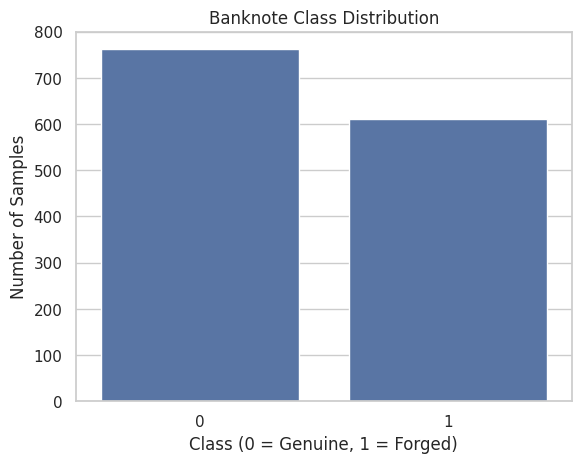

In [5]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

sns.countplot(data=df, x="class")
plt.title("Banknote Class Distribution")
plt.xlabel("Class (0 = Genuine, 1 = Forged)")
plt.ylabel("Number of Samples")
plt.show()

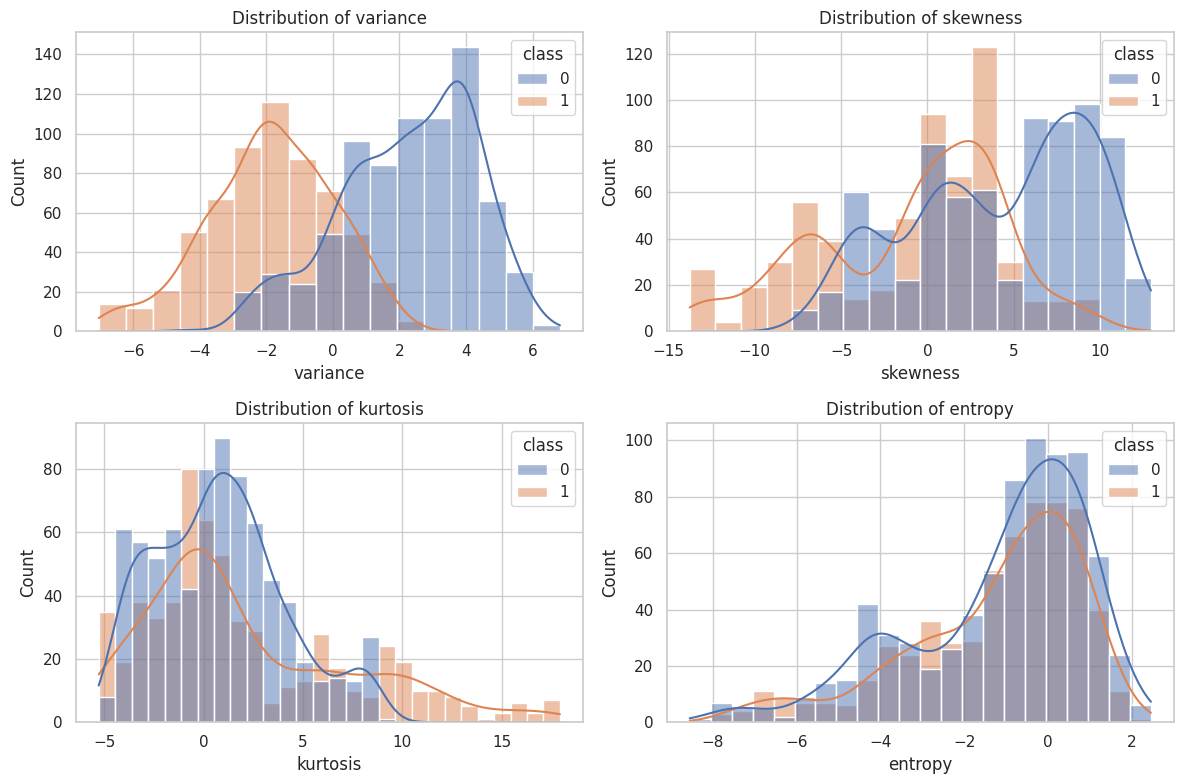

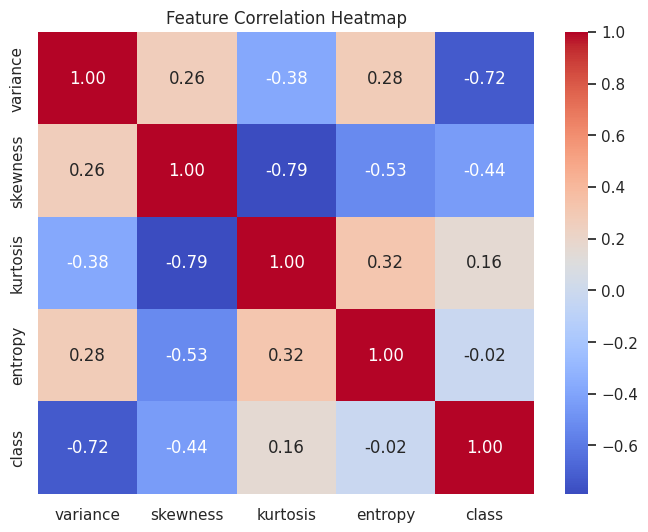

In [6]:
features = ["variance", "skewness", "kurtosis", "entropy"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), features):
    sns.histplot(
        data=df,
        x=feature,
        hue="class",
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [7]:
X = df[features].values.astype(np.float64)
y = df["class"].values.reshape(-1, 1).astype(np.float64)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Training labels:", y_train.shape)

Training samples: 1097
Testing samples: 275
Number of features: 4
Training labels: (1097, 1)


Perceptron Accuracy: 0.9854545454545455


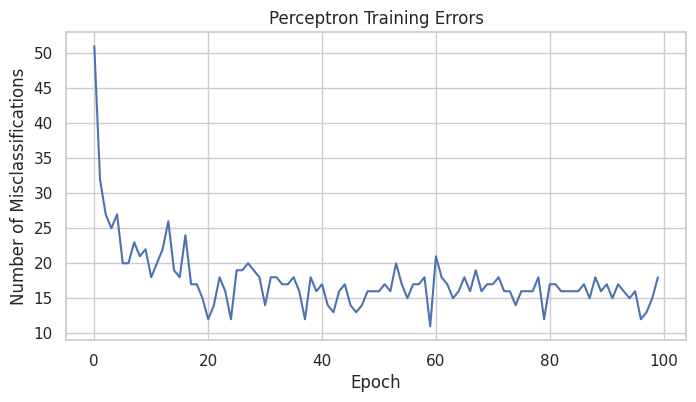

In [8]:
class Perceptron:
    def __init__(self, n_features, learning_rate=0.01):
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.learning_rate = learning_rate

    def activation(self, z):
        return np.where(z >= 0, 1, 0)

    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.activation(z)

    def fit(self, X, y, epochs=100):
        errors = []

        for epoch in range(epochs):
            total_errors = 0

            for xi, target in zip(X, y):
                prediction = self.predict(xi)
                error = int(target) - int(prediction)

                self.weights += (
                    self.learning_rate * error * xi
                )
                self.bias += self.learning_rate * error

                total_errors += int(error != 0)

            errors.append(total_errors)

        return errors


perceptron = Perceptron(n_features=4)

perceptron_errors = perceptron.fit(
    X_train,
    y_train.ravel(),
    epochs=100
)

perceptron_predictions = perceptron.predict(X_test)

print(
    "Perceptron Accuracy:",
    accuracy_score(y_test.ravel(), perceptron_predictions)
)

plt.figure(figsize=(8, 4))
plt.plot(perceptron_errors)
plt.title("Perceptron Training Errors")
plt.xlabel("Epoch")
plt.ylabel("Number of Misclassifications")
plt.show()

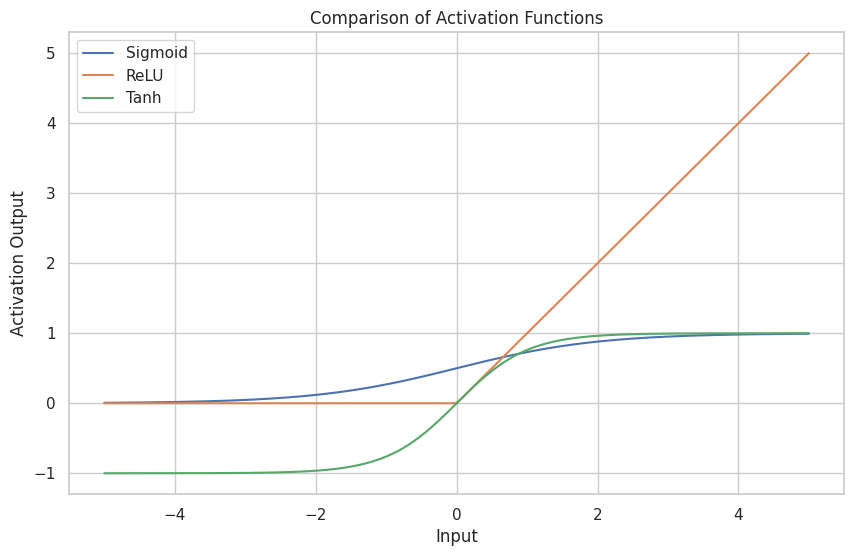

In [9]:
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)


def relu(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)


def tanh(x):
    return np.tanh(x)


def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2


x_values = np.linspace(-5, 5, 200)

plt.figure(figsize=(10, 6))

plt.plot(x_values, sigmoid(x_values), label="Sigmoid")
plt.plot(x_values, relu(x_values), label="ReLU")
plt.plot(x_values, tanh(x_values), label="Tanh")

plt.title("Comparison of Activation Functions")
plt.xlabel("Input")
plt.ylabel("Activation Output")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-12

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )


# Example
actual = np.array([[1], [0], [1], [0]])

predicted = np.array([
    [0.9],
    [0.2],
    [0.8],
    [0.1]
])

print("MSE Loss:", mse_loss(actual, predicted))
print(
    "Binary Cross-Entropy Loss:",
    binary_cross_entropy(actual, predicted)
)

MSE Loss: 0.024999999999999994
Binary Cross-Entropy Loss: 0.16425203348601802


In [11]:
class NeuralNetwork:
    def __init__(
        self,
        input_size=4,
        hidden1=16,
        hidden2=8,
        learning_rate=0.01,
        optimizer="adam",
        seed=42
    ):
        self.learning_rate = learning_rate
        self.optimizer = optimizer.lower()

        if self.optimizer not in ("sgd", "adam"):
            raise ValueError("Optimizer must be 'sgd' or 'adam'")

        rng = np.random.default_rng(seed)

        # He initialization for ReLU hidden layers
        self.W1 = rng.standard_normal(
            (input_size, hidden1)
        ) * np.sqrt(2 / input_size)

        self.b1 = np.zeros((1, hidden1))

        self.W2 = rng.standard_normal(
            (hidden1, hidden2)
        ) * np.sqrt(2 / hidden1)

        self.b2 = np.zeros((1, hidden2))

        self.W3 = rng.standard_normal(
            (hidden2, 1)
        ) * np.sqrt(1 / hidden2)

        self.b3 = np.zeros((1, 1))

        # Adam optimizer parameters
        self.beta1 = 0.9
        self.beta2 = 0.999
        self.epsilon = 1e-8
        self.t = 0

        self.m = {}
        self.v = {}

        for name in ["W1", "b1", "W2", "b2", "W3", "b3"]:
            self.m[name] = np.zeros_like(getattr(self, name))
            self.v[name] = np.zeros_like(getattr(self, name))

        self.loss_history = []
        self.accuracy_history = []

    # Forward propagation
    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = relu(self.Z1)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = relu(self.Z2)

        self.Z3 = self.A2 @ self.W3 + self.b3
        self.A3 = sigmoid(self.Z3)

        return self.A3

    # Backward propagation
    def backward(self, X, y):
        m = X.shape[0]

        # Sigmoid + binary cross-entropy derivative
        dZ3 = self.A3 - y

        dW3 = (self.A2.T @ dZ3) / m
        db3 = np.mean(dZ3, axis=0, keepdims=True)

        dA2 = dZ3 @ self.W3.T
        dZ2 = dA2 * relu_derivative(self.Z2)

        dW2 = (self.A1.T @ dZ2) / m
        db2 = np.mean(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * relu_derivative(self.Z1)

        dW1 = (X.T @ dZ1) / m
        db1 = np.mean(dZ1, axis=0, keepdims=True)

        return {
            "W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3
        }

    # Weight updates using SGD or Adam
    def update_weights(self, gradients):
        if self.optimizer == "adam":
            self.t += 1

        for name, grad in gradients.items():
            param = getattr(self, name)

            if self.optimizer == "sgd":
                param -= self.learning_rate * grad

            elif self.optimizer == "adam":
                self.m[name] = (
                    self.beta1 * self.m[name]
                    + (1 - self.beta1) * grad
                )

                self.v[name] = (
                    self.beta2 * self.v[name]
                    + (1 - self.beta2) * (grad ** 2)
                )

                m_hat = self.m[name] / (
                    1 - self.beta1 ** self.t
                )

                v_hat = self.v[name] / (
                    1 - self.beta2 ** self.t
                )

                param -= (
                    self.learning_rate * m_hat
                    / (np.sqrt(v_hat) + self.epsilon)
                )

    # Training loop
    def train(
        self,
        X,
        y,
        epochs=300,
        batch_size=32,
        verbose=True
    ):
        rng = np.random.default_rng(123)

        self.loss_history = []
        self.accuracy_history = []

        for epoch in range(epochs):
            indices = rng.permutation(len(X))

            X_shuffled = X[indices]
            y_shuffled = y[indices]

            for start in range(0, len(X), batch_size):
                end = start + batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                self.forward(X_batch)

                gradients = self.backward(
                    X_batch,
                    y_batch
                )

                self.update_weights(gradients)

            # Evaluate on the full training set
            predictions = self.forward(X)

            loss = binary_cross_entropy(y, predictions)

            predicted_labels = (
                predictions >= 0.5
            ).astype(int)

            accuracy = np.mean(predicted_labels == y)

            self.loss_history.append(loss)
            self.accuracy_history.append(accuracy)

            if verbose and (
                (epoch + 1) % 50 == 0 or epoch == 0
            ):
                print(
                    f"Epoch {epoch+1}/{epochs} | "
                    f"Loss: {loss:.4f} | "
                    f"Accuracy: {accuracy:.4f}"
                )

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)


print("Neural network class created successfully!")

Neural network class created successfully!


In [12]:
sgd_model = NeuralNetwork(
    input_size=4,
    hidden1=16,
    hidden2=8,
    learning_rate=0.01,
    optimizer="sgd"
)

print("Training Neural Network with SGD...\n")

sgd_model.train(
    X_train,
    y_train,
    epochs=300,
    batch_size=32
)

sgd_predictions = sgd_model.predict(X_test)

sgd_accuracy = accuracy_score(
    y_test.ravel(),
    sgd_predictions.ravel()
)

print("\nSGD Test Accuracy:", round(sgd_accuracy, 4))

Training Neural Network with SGD...

Epoch 1/300 | Loss: 0.6735 | Accuracy: 0.5469
Epoch 50/300 | Loss: 0.0483 | Accuracy: 0.9836
Epoch 100/300 | Loss: 0.0260 | Accuracy: 0.9863
Epoch 150/300 | Loss: 0.0168 | Accuracy: 0.9927
Epoch 200/300 | Loss: 0.0112 | Accuracy: 1.0000
Epoch 250/300 | Loss: 0.0079 | Accuracy: 1.0000
Epoch 300/300 | Loss: 0.0058 | Accuracy: 1.0000

SGD Test Accuracy: 1.0


In [13]:
adam_model = NeuralNetwork(
    input_size=4,
    hidden1=16,
    hidden2=8,
    learning_rate=0.001,
    optimizer="adam"
)

print("Training Neural Network with Adam...\n")

adam_model.train(
    X_train,
    y_train,
    epochs=300,
    batch_size=32
)

adam_predictions = adam_model.predict(X_test)

adam_accuracy = accuracy_score(
    y_test.ravel(),
    adam_predictions.ravel()
)

print("\nAdam Test Accuracy:", round(adam_accuracy, 4))

Training Neural Network with Adam...

Epoch 1/300 | Loss: 0.6269 | Accuracy: 0.7019
Epoch 50/300 | Loss: 0.0053 | Accuracy: 1.0000
Epoch 100/300 | Loss: 0.0008 | Accuracy: 1.0000
Epoch 150/300 | Loss: 0.0002 | Accuracy: 1.0000
Epoch 200/300 | Loss: 0.0001 | Accuracy: 1.0000
Epoch 250/300 | Loss: 0.0000 | Accuracy: 1.0000
Epoch 300/300 | Loss: 0.0000 | Accuracy: 1.0000

Adam Test Accuracy: 1.0


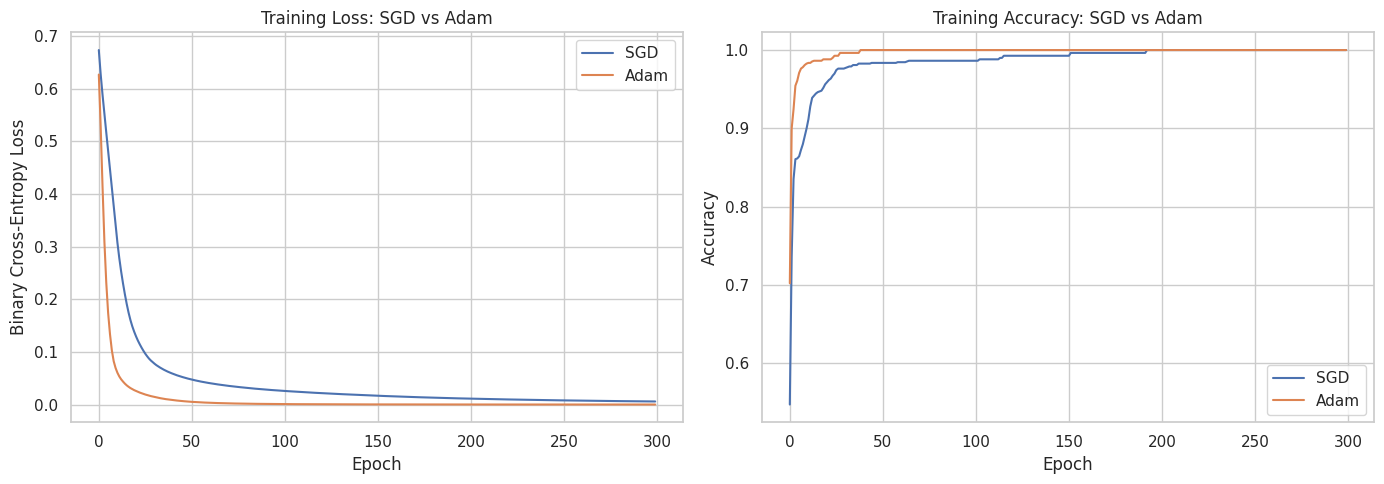

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    sgd_model.loss_history,
    label="SGD"
)

axes[0].plot(
    adam_model.loss_history,
    label="Adam"
)

axes[0].set_title("Training Loss: SGD vs Adam")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(
    sgd_model.accuracy_history,
    label="SGD"
)

axes[1].plot(
    adam_model.accuracy_history,
    label="Adam"
)

axes[1].set_title("Training Accuracy: SGD vs Adam")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
comparison = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Learning Rate": [0.01, 0.001],
    "Epochs": [300, 300],
    "Final Training Loss": [
        sgd_model.loss_history[-1],
        adam_model.loss_history[-1]
    ],
    "Test Accuracy": [
        sgd_accuracy,
        adam_accuracy
    ]
})

display(comparison.round(4))

,Optimizer,Learning Rate,Epochs,Final Training Loss,Test Accuracy
0,SGD,0.010,300,0.0058,1.0
1,Adam,0.001,300,0.0000,1.0


In [16]:
final_model = adam_model

y_true = y_test.ravel()
y_pred = final_model.predict(X_test).ravel()
y_prob = final_model.predict_proba(X_test).ravel()

print("FINAL MODEL EVALUATION")
print("-" * 40)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Genuine", "Forged"]
    )
)

FINAL MODEL EVALUATION
----------------------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0

Classification Report:

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00       153
      Forged       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



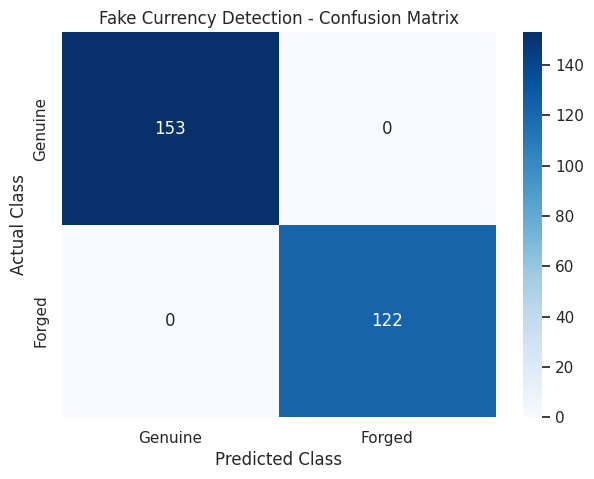

In [17]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Forged"],
    yticklabels=["Genuine", "Forged"]
)

plt.title("Fake Currency Detection - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

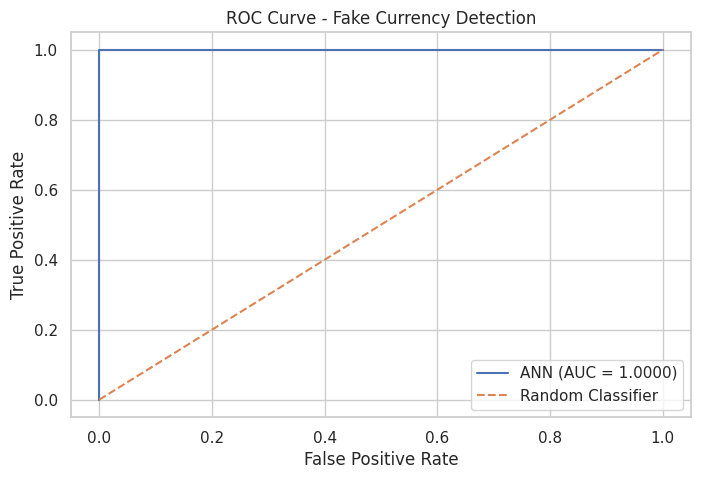

In [18]:
fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ANN (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fake Currency Detection")
plt.legend()
plt.grid(True)

plt.show()

In [19]:
import pickle
import joblib

# Save using Pickle
with open("currency_ann_pickle.pkl", "wb") as file:
    pickle.dump(final_model, file)

# Save using Joblib
joblib.dump(
    final_model,
    "currency_ann_joblib.joblib"
)

# Save the scaler
joblib.dump(
    scaler,
    "currency_scaler.joblib"
)

print("Model saved using Pickle.")
print("Model saved using Joblib.")
print("Scaler saved successfully.")

Model saved using Pickle.
Model saved using Joblib.
Scaler saved successfully.


In [20]:
# Load Pickle model
with open("currency_ann_pickle.pkl", "rb") as file:
    loaded_pickle_model = pickle.load(file)

# Load Joblib model
loaded_joblib_model = joblib.load(
    "currency_ann_joblib.joblib"
)

# Load scaler
loaded_scaler = joblib.load(
    "currency_scaler.joblib"
)

# Verify loaded model predictions
pickle_predictions = loaded_pickle_model.predict(X_test)
joblib_predictions = loaded_joblib_model.predict(X_test)

print(
    "Pickle Model Accuracy:",
    accuracy_score(
        y_test.ravel(),
        pickle_predictions.ravel()
    )
)

print(
    "Joblib Model Accuracy:",
    accuracy_score(
        y_test.ravel(),
        joblib_predictions.ravel()
    )
)

print(
    "Predictions identical:",
    np.array_equal(
        pickle_predictions,
        joblib_predictions
    )
)

Pickle Model Accuracy: 1.0
Joblib Model Accuracy: 1.0
Predictions identical: True


In [21]:
# Choose a sample from the held-out test set
sample_index = 0

# Original unscaled feature values
sample_raw = X_test[sample_index:sample_index+1]

# Convert back to original feature scale
sample_original = scaler.inverse_transform(sample_raw)

# Apply the loaded scaler
sample_scaled = loaded_scaler.transform(sample_original)

# Make prediction
prediction = loaded_joblib_model.predict(sample_scaled)[0, 0]

probability = loaded_joblib_model.predict_proba(
    sample_scaled
)[0, 0]

actual = int(y_test[sample_index, 0])

print("BANKNOTE AUTHENTICATION RESULT")
print("-" * 40)

print("Input Features:", sample_original[0])

print(
    "Actual Class:",
    "Forged" if actual == 1 else "Genuine"
)

print(
    "Predicted Class:",
    "Forged" if prediction == 1 else "Genuine"
)

print(
    f"Predicted Probability of Forged Class: "
    f"{probability:.2%}"
)

BANKNOTE AUTHENTICATION RESULT
----------------------------------------
Input Features: [ 2.3718    7.4908    0.015989 -1.7414  ]
Actual Class: Genuine
Predicted Class: Genuine
Predicted Probability of Forged Class: 0.00%


In [22]:
sample_count = 10

samples = X_test[:sample_count]
actual_labels = y_test[:sample_count].ravel()

predicted_labels = loaded_joblib_model.predict(
    samples
).ravel()

probabilities = loaded_joblib_model.predict_proba(
    samples
).ravel()

results = pd.DataFrame({
    "Sample": range(1, sample_count + 1),
    "Actual": [
        "Forged" if x == 1 else "Genuine"
        for x in actual_labels
    ],
    "Predicted": [
        "Forged" if x == 1 else "Genuine"
        for x in predicted_labels
    ],
    "Forged Probability": probabilities.round(4)
})

results["Correct"] = (
    results["Actual"] == results["Predicted"]
)

display(results)

,Sample,Actual,Predicted,Forged Probability,Correct
0,1,Genuine,Genuine,0.0,True
1,2,Forged,Forged,1.0,True
2,3,Genuine,Genuine,0.0,True
3,4,Forged,Forged,1.0,True
4,5,Forged,Forged,1.0,True
5,6,Forged,Forged,1.0,True
6,7,Genuine,Genuine,0.0,True
7,8,Genuine,Genuine,0.0,True
8,9,Genuine,Genuine,0.0,True
9,10,Forged,Forged,1.0,True


In [23]:
from google.colab import files

files.download("currency_ann_pickle.pkl")
files.download("currency_ann_joblib.joblib")
files.download("currency_scaler.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this experiment, an Artificial Neural Network (ANN) was developed from scratch using NumPy for banknote authentication.

The experiment demonstrated the working of a perceptron, activation functions, forward propagation, backpropagation, loss functions, and optimization algorithms.

Two optimizers, Stochastic Gradient Descent (SGD) and Adam, were implemented and compared using training loss and classification accuracy.

The trained neural network was evaluated using accuracy, precision, recall, F1-score, a confusion matrix, and an ROC curve.

Finally, the trained model was saved and loaded using Pickle and Joblib, demonstrating the basic principles of machine learning model persistence.

**Result:** A complete neural network training and evaluation pipeline was successfully implemented using NumPy, covering all the required concepts.